# World Population Mapping

## Overview

Mapped 2024 country-level population and population density worldwide by joining World Bank population statistics to a world country boundary dataset. Choropleth maps show where people live, from raw population counts to density on a logarithmic scale.

**Study Area:** Global (all countries)  
**Duration:** [Start month/year – End month/year]  
**Role:** [Solo project / Team lead / Contributor]  
**Status:** [Completed / In progress]

---

## Methods & Tools

**Data Sources**

- World country boundaries (GeoJSON): [johan/world.geo.json](https://github.com/johan/world.geo.json)
- Population, total (SP.POP.TOTL): [World Bank API](https://api.worldbank.org/v2/country/all/indicator/SP.POP.TOTL?format=json&per_page=20000)

**Processing Steps**

1. Load and inspect world country boundaries
2. Load population data from the World Bank API and check for missing values
3. Filter to 2024 and join population to boundaries on ISO3 country codes
4. Map total population by country
5. Reproject to an equal-area CRS, compute population density, and map it on a log scale

**Tools Used**

| Tool | Purpose |
|------|---------|
| geopandas | Reading boundaries, spatial joins, reprojection, area calculation |
| pandas | Data loading, cleaning, aggregation |
| requests | Fetching data from the World Bank API |
| matplotlib | Static maps |

---

## Setup

In [ ]:
import geopandas as gpd
import matplotlib.pyplot as plt

---

## Data

World country boundaries and World Bank population records (1960–2025).

In [ ]:
url = "https://raw.githubusercontent.com/johan/world.geo.json/master/countries.geo.json"
world = gpd.read_file(url)

In [ ]:
print(world.head()) # First 5 rows
print(world.info()) # quick summary of GeoDataFrame
print(world.crs) # Coordinate Reference System

    id                  name  \
0  AFG           Afghanistan   
1  AGO                Angola   
2  ALB               Albania   
3  ARE  United Arab Emirates   
4  ARG             Argentina   

                                            geometry  
0  POLYGON ((61.21082 35.65007, 62.23065 35.27066...  
1  MULTIPOLYGON (((16.32653 -5.87747, 16.57318 -6...  
2  POLYGON ((20.59025 41.8554, 20.46318 41.51509,...  
3  POLYGON ((51.57952 24.2455, 51.75744 24.29407,...  
4  MULTIPOLYGON (((-65.5 -55.2, -66.45 -55.25, -6...  
<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype   
---  ------    --------------  -----   
 0   id        180 non-null    str     
 1   name      180 non-null    str     
 2   geometry  180 non-null    geometry
dtypes: geometry(1), str(2)
memory usage: 4.3 KB
None
EPSG:4326


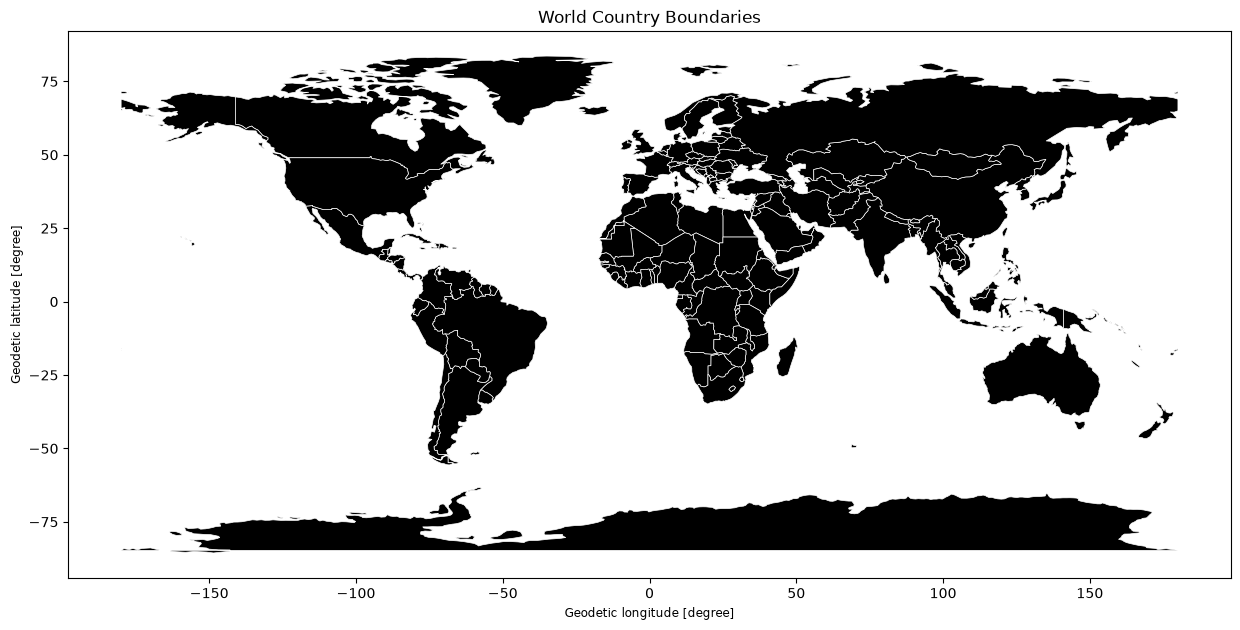

In [91]:
world.plot(
    figsize=(15, 8),
    color="black",
    edgecolor="white",
    linewidth=0.5
)

plt.title("World Country Boundaries")
plt.show()

In [60]:
# Number of rows and columns
print(world.shape)

# Column names
print(world.columns)

# Geometry types
print(world.geometry.geom_type.value_counts())

# Missing values
print(world.isnull().sum())

(180, 3)
Index(['id', 'name', 'geometry'], dtype='str')
Polygon         150
MultiPolygon     30
Name: count, dtype: int64
id          0
name        0
geometry    0
dtype: int64


We'll use the World Bank's population dataset.

Dataset: Population, total (SP.POP.TOTL)

URL: https://api.worldbank.org/v2/country/all/indicator/SP.POP.TOTL?format=json&per_page=20000

This API provides population statistics by country and year.

In [ ]:
import requests
import pandas as pd

url = "https://api.worldbank.org/v2/country/all/indicator/SP.POP.TOTL?format=json&per_page=20000"

response = requests.get(url)
response.raise_for_status()

json_data = response.json()

# Flatten into Tabular & Extract the actual population records
population = pd.json_normalize(json_data[1])

print(population.head())
print(population.columns)

  countryiso3code  date        value unit obs_status  decimal indicator.id  \
0             AFE  2025  788844284.0                        0  SP.POP.TOTL   
1             AFE  2024  769280888.0                        0  SP.POP.TOTL   
2             AFE  2023  750491370.0                        0  SP.POP.TOTL   
3             AFE  2022  731821393.0                        0  SP.POP.TOTL   
4             AFE  2021  713090928.0                        0  SP.POP.TOTL   

     indicator.value country.id                country.value  
0  Population, total         ZH  Africa Eastern and Southern  
1  Population, total         ZH  Africa Eastern and Southern  
2  Population, total         ZH  Africa Eastern and Southern  
3  Population, total         ZH  Africa Eastern and Southern  
4  Population, total         ZH  Africa Eastern and Southern  
Index(['countryiso3code', 'date', 'value', 'unit', 'obs_status', 'decimal',
       'indicator.id', 'indicator.value', 'country.id', 'country.value'],
   

In [ ]:
# Dataset dimensions
print(population.shape)

# Column names
print(population.columns.tolist())

# Dataset information
population.info()

# Missing values
print(population.isnull().sum()) #96 missing pop values. Have to check for which year.

# Statistical summary
print(population.describe())

(17556, 10)
['countryiso3code', 'date', 'value', 'unit', 'obs_status', 'decimal', 'indicator.id', 'indicator.value', 'country.id', 'country.value']
<class 'pandas.DataFrame'>
RangeIndex: 17556 entries, 0 to 17555
Data columns (total 10 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   countryiso3code  17556 non-null  str    
 1   date             17556 non-null  str    
 2   value            17460 non-null  float64
 3   unit             17556 non-null  str    
 4   obs_status       17556 non-null  str    
 5   decimal          17556 non-null  int64  
 6   indicator.id     17556 non-null  str    
 7   indicator.value  17556 non-null  str    
 8   country.id       17556 non-null  str    
 9   country.value    17556 non-null  str    
dtypes: float64(1), int64(1), str(8)
memory usage: 1.3 MB
countryiso3code     0
date                0
value              96
unit                0
obs_status          0
decimal             0
indicator.id

In [112]:
print(population[
    ["country.id", "country.value", "countryiso3code"]
].head(10))

  country.id                country.value countryiso3code
0         ZH  Africa Eastern and Southern             AFE
1         ZH  Africa Eastern and Southern             AFE
2         ZH  Africa Eastern and Southern             AFE
3         ZH  Africa Eastern and Southern             AFE
4         ZH  Africa Eastern and Southern             AFE
5         ZH  Africa Eastern and Southern             AFE
6         ZH  Africa Eastern and Southern             AFE
7         ZH  Africa Eastern and Southern             AFE
8         ZH  Africa Eastern and Southern             AFE
9         ZH  Africa Eastern and Southern             AFE


In [109]:
# We have Population data from 1960 - 2025
print(population["date"].unique())

# As expected Trend
print(population["date"].min())
print(population["date"].max())

<StringArray>
['2025', '2024', '2023', '2022', '2021', '2020', '2019', '2018', '2017',
 '2016', '2015', '2014', '2013', '2012', '2011', '2010', '2009', '2008',
 '2007', '2006', '2005', '2004', '2003', '2002', '2001', '2000', '1999',
 '1998', '1997', '1996', '1995', '1994', '1993', '1992', '1991', '1990',
 '1989', '1988', '1987', '1986', '1985', '1984', '1983', '1982', '1981',
 '1980', '1979', '1978', '1977', '1976', '1975', '1974', '1973', '1972',
 '1971', '1970', '1969', '1968', '1967', '1966', '1965', '1964', '1963',
 '1962', '1961', '1960']
Length: 66, dtype: str
1960
2025


---

## Analysis

### Cleaning missing values

CHECKING MISSING VALUES IN THE POPULATION DATASET AND REMOVING THEM.

In [134]:
print(
    population["date"].value_counts().sort_index(ascending=False).head(10)
)

date
2025    266
2024    266
2023    266
2022    266
2021    266
2020    266
2019    266
2018    266
2017    266
2016    266
Name: count, dtype: int64


In [125]:
missing = population[population["value"].isnull()]

print(missing[
    ["country.value", "countryiso3code", "date"]
].head(20))

       country.value countryiso3code  date
2310  Not classified                  2025
2311  Not classified                  2024
2312  Not classified                  2023
2313  Not classified                  2022
2314  Not classified                  2021
2315  Not classified                  2020
2316  Not classified                  2019
2317  Not classified                  2018
2318  Not classified                  2017
2319  Not classified                  2016
2320  Not classified                  2015
2321  Not classified                  2014
2322  Not classified                  2013
2323  Not classified                  2012
2324  Not classified                  2011
2325  Not classified                  2010
2326  Not classified                  2009
2327  Not classified                  2008
2328  Not classified                  2007
2329  Not classified                  2006


In [136]:
print(population["country.value"].nunique())

266


In [137]:
# Inspect which entities and years have missing values
print(
    missing[["country.value", "countryiso3code", "date"]]
    .to_string(index=False)
)

     country.value countryiso3code date
    Not classified                 2025
    Not classified                 2024
    Not classified                 2023
    Not classified                 2022
    Not classified                 2021
    Not classified                 2020
    Not classified                 2019
    Not classified                 2018
    Not classified                 2017
    Not classified                 2016
    Not classified                 2015
    Not classified                 2014
    Not classified                 2013
    Not classified                 2012
    Not classified                 2011
    Not classified                 2010
    Not classified                 2009
    Not classified                 2008
    Not classified                 2007
    Not classified                 2006
    Not classified                 2005
    Not classified                 2004
    Not classified                 2003
    Not classified                 2002


In [ ]:
missing[missing["country.value"] == "Not classified"] # rest 33 for West Bank and Gaza

,countryiso3code,date,value,unit,obs_status,decimal,indicator.id,indicator.value,country.id,country.value
2310,,2025,NaN,,,0,SP.POP.TOTL,"Population, total",XY,Not classified
2311,,2024,NaN,,,0,SP.POP.TOTL,"Population, total",XY,Not classified
2312,,2023,NaN,,,0,SP.POP.TOTL,"Population, total",XY,Not classified
2313,,2022,NaN,,,0,SP.POP.TOTL,"Population, total",XY,Not classified
2314,,2021,NaN,,,0,SP.POP.TOTL,"Population, total",XY,Not classified
...,...,...,...,...,...,...,...,...,...,...
2371,,1964,NaN,,,0,SP.POP.TOTL,"Population, total",XY,Not classified
2372,,1963,NaN,,,0,SP.POP.TOTL,"Population, total",XY,Not classified
2373,,1962,NaN,,,0,SP.POP.TOTL,"Population, total",XY,Not classified
2374,,1961,NaN,,,0,SP.POP.TOTL,"Population, total",XY,Not classified


In [139]:
population_2024 = population[population["date"] == "2024"].copy()

In [140]:
print(population_2024.shape)
print(population_2024.head())

(266, 10)
    countryiso3code  date        value unit obs_status  decimal indicator.id  \
1               AFE  2024  769280888.0                        0  SP.POP.TOTL   
67              AFW  2024  520655398.0                        0  SP.POP.TOTL   
133             ARB  2024  492612632.0                        0  SP.POP.TOTL   
199             CSS  2024    4539060.0                        0  SP.POP.TOTL   
265             CEB  2024  100061963.0                        0  SP.POP.TOTL   

       indicator.value country.id                   country.value  
1    Population, total         ZH     Africa Eastern and Southern  
67   Population, total         ZI      Africa Western and Central  
133  Population, total         1A                      Arab World  
199  Population, total         S3          Caribbean small states  
265  Population, total         B8  Central Europe and the Baltics  


In [141]:
print(
    population_2024[
        ["country.value", "countryiso3code", "value"]
    ].to_string(index=False)
)

                                                            country.value countryiso3code        value
                                              Africa Eastern and Southern             AFE  769280888.0
                                               Africa Western and Central             AFW  520655398.0
                                                               Arab World             ARB  492612632.0
                                                   Caribbean small states             CSS    4539060.0
                                           Central Europe and the Baltics             CEB  100061963.0
                                               Early-demographic dividend             EAR 3552306404.0
                                                      East Asia & Pacific             EAS 2388319468.0
                              East Asia & Pacific (excluding high income)             EAP 2141122258.0
                               East Asia & Pacific (IDA & IBRD countries)

### Joining population to boundaries

In [ ]:
# Checking ISO3 codes for joining both the fields. Population & World
# Population column = countryiso3code & World column = id
print(world.columns.tolist())
print(world.head(10))

['id', 'name', 'geometry']
    id                                 name  \
0  AFG                          Afghanistan   
1  AGO                               Angola   
2  ALB                              Albania   
3  ARE                 United Arab Emirates   
4  ARG                            Argentina   
5  ARM                              Armenia   
6  ATA                           Antarctica   
7  ATF  French Southern and Antarctic Lands   
8  AUS                            Australia   
9  AUT                              Austria   

                                            geometry  
0  POLYGON ((61.21082 35.65007, 62.23065 35.27066...  
1  MULTIPOLYGON (((16.32653 -5.87747, 16.57318 -6...  
2  POLYGON ((20.59025 41.8554, 20.46318 41.51509,...  
3  POLYGON ((51.57952 24.2455, 51.75744 24.29407,...  
4  MULTIPOLYGON (((-65.5 -55.2, -66.45 -55.25, -6...  
5  POLYGON ((43.58275 41.09214, 44.97248 41.24813...  
6  MULTIPOLYGON (((-59.5721 -80.04018, -59.86585 ...  
7  POLYGON ((68

In [144]:
# Get all country codes present in the world map
world_codes = world["id"]

# Keep population records whose codes exist in the world dataset
population_countries = population_2024[
    population_2024["countryiso3code"].isin(world_codes)
].copy()

print(population_countries.shape)

(171, 10)


In [145]:
print("Original population records:", len(population_2024))
print("Matched population records:", len(population_countries))

print(
    population_countries[
        ["country.value", "countryiso3code", "value"]
    ].head(10)
)

Original population records: 266
Matched population records: 171
     country.value countryiso3code       value
3235   Afghanistan             AFG  42647492.0
3301       Albania             ALB   2377128.0
3367       Algeria             DZA  46814308.0
3565        Angola             AGO  37885849.0
3697     Argentina             ARG  45696159.0
3763       Armenia             ARM   3033500.0
3895     Australia             AUS  27194286.0
3961       Austria             AUT   9177982.0
4027    Azerbaijan             AZE  10202830.0
4093  Bahamas, The             BHS    401283.0


In [146]:
# JOIN FIELD
world_population = world.merge(
    population_countries,
    left_on="id",
    right_on="countryiso3code",
    how="left"
)

In [148]:
world_population.columns.to_list()

['id',
 'name',
 'geometry',
 'countryiso3code',
 'date',
 'value',
 'unit',
 'obs_status',
 'decimal',
 'indicator.id',
 'indicator.value',
 'country.id',
 'country.value']

In [155]:
# Dropping unnesassary columns
# world_population = world_population.drop(columns=["unit", "obs_status", "decimal"])

In [153]:
world_population.head()

,id,name,geometry,countryiso3code,date,value,indicator.id,indicator.value,country.id,country.value
0,AFG,Afghanistan,"POLYGON ((61.21082 35.65007, 62.23065 35.27066...",AFG,2024,42647492.0,SP.POP.TOTL,"Population, total",AF,Afghanistan
1,AGO,Angola,"MULTIPOLYGON (((16.32653 -5.87747, 16.57318 -6...",AGO,2024,37885849.0,SP.POP.TOTL,"Population, total",AO,Angola
2,ALB,Albania,"POLYGON ((20.59025 41.8554, 20.46318 41.51509,...",ALB,2024,2377128.0,SP.POP.TOTL,"Population, total",AL,Albania
3,ARE,United Arab Emirates,"POLYGON ((51.57952 24.2455, 51.75744 24.29407,...",ARE,2024,10986400.0,SP.POP.TOTL,"Population, total",AE,United Arab Emirates
4,ARG,Argentina,"MULTIPOLYGON (((-65.5 -55.2, -66.45 -55.25, -6...",ARG,2024,45696159.0,SP.POP.TOTL,"Population, total",AR,Argentina


In [157]:
print("Shape:", world_population.shape)

print("\nMissing population values:")
print(world_population["value"].isna().sum())

print("\nSample records:")
print(
    world_population[
        ["name", "countryiso3code", "value"]
    ].head(15)
)

Shape: (180, 10)

Missing population values:
9

Sample records:
                                   name countryiso3code       value
0                           Afghanistan             AFG  42647492.0
1                                Angola             AGO  37885849.0
2                               Albania             ALB   2377128.0
3                  United Arab Emirates             ARE  10986400.0
4                             Argentina             ARG  45696159.0
5                               Armenia             ARM   3033500.0
6                            Antarctica             NaN         NaN
7   French Southern and Antarctic Lands             NaN         NaN
8                             Australia             AUS  27194286.0
9                               Austria             AUT   9177982.0
10                           Azerbaijan             AZE  10202830.0
11                              Burundi             BDI  14047786.0
12                              Belgium             

In [158]:
missing_countries = world_population[
    world_population["value"].isna()
]

print(
    missing_countries[["id", "name"]]
    .to_string(index=False)
)

   id                                name
  ATA                          Antarctica
  ATF French Southern and Antarctic Lands
  -99                     Northern Cyprus
  FLK                    Falkland Islands
  GUF                       French Guiana
CS-KM                              Kosovo
  ESH                      Western Sahara
  -99                          Somaliland
  TWN                              Taiwan


In [159]:
# Some are not inhabited and some have different id and country.code. 

In [160]:
print(world_population.crs)

EPSG:4326


---

## Spatial Distribution

### Total population by country (2024)

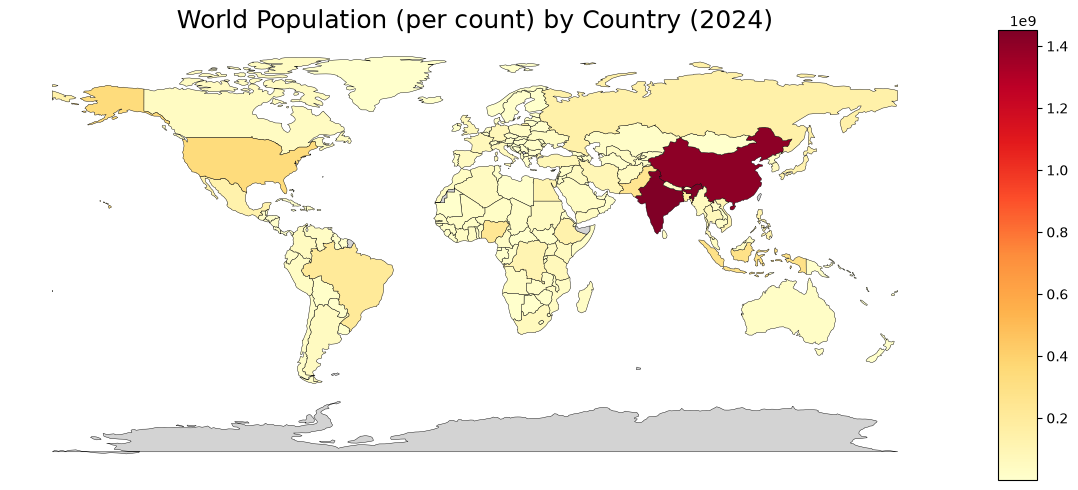

In [162]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(15, 10))

world_population.plot(
    column="value",
    cmap="YlOrRd",
    legend=True,
    figsize=(15, 10),
    edgecolor="black",
    linewidth=0.3,
    missing_kwds={
        "color": "lightgrey",
        "label": "No population data"
    },
    ax=ax
)

ax.set_title(
    "World Population (per count) by Country (2024)",
    fontsize=18
)

ax.set_axis_off()

plt.show()

### Population density by country (2024)

In [163]:
# FOR BETTER VISUALISATION WE WILL USE POPULATION DENSITY

In [164]:
world_population_projected = world_population.to_crs("EPSG:8857")

In [165]:
# Calculate area in square kilometres
world_population_projected["area_km2"] = (
    world_population_projected.geometry.area / 1_000_000
)

In [166]:
world_population_projected["population_density"] = (
    world_population_projected["value"] /
    world_population_projected["area_km2"]
)

In [167]:
print(
    world_population_projected[
        ["name", "value", "area_km2", "population_density"]
    ].sort_values(
        "population_density", ascending=False
    ).head(15)
)

            name         value      area_km2  population_density
107        Malta  5.688470e+05  2.738709e+02         2077.062448
15    Bangladesh  1.735624e+08  1.337125e+05         1298.026632
175    West Bank  5.289152e+06  5.036413e+03         1050.182372
21       Bermuda  6.463600e+04  6.533595e+01          989.286939
138       Rwanda  1.425657e+07  2.336457e+04          610.178770
93       Lebanon  5.805962e+06  1.009604e+04          575.073001
11       Burundi  1.404779e+07  2.624650e+04          535.225101
89   South Korea  5.175106e+07  9.901951e+04          522.635050
75         India  1.450936e+09  3.142896e+06          461.655638
120  Netherlands  1.799348e+07  3.996233e+04          450.261122
80        Israel  1.000220e+07  2.303020e+04          434.307948
72         Haiti  1.177256e+07  2.853660e+04          412.542368
128  Philippines  1.158437e+08  2.923207e+05          396.289639
12       Belgium  1.185861e+07  3.012913e+04          393.592866
131  Puerto Rico  3.20252

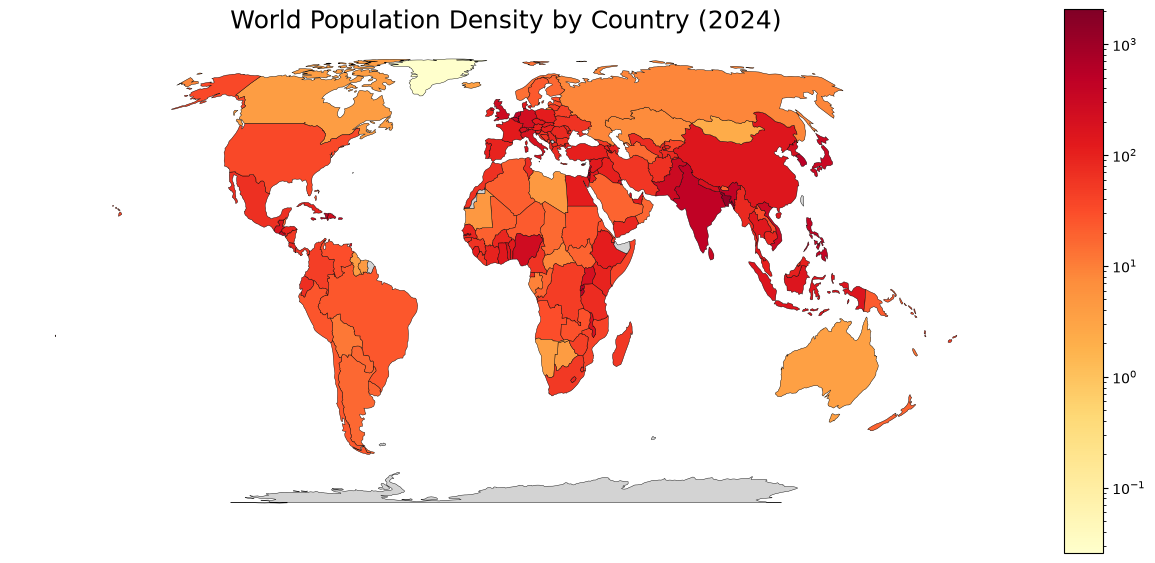

In [ ]:
from matplotlib.colors import LogNorm

# Keep only positive density values for logarithmic scaling
positive_density = world_population_projected[
    "population_density"
].dropna()

positive_density = positive_density[positive_density > 0]

# Create logarithmic normalization (useful)
norm = LogNorm(
    vmin=positive_density.min(),
    vmax=positive_density.max()
)

# Create the map
fig, ax = plt.subplots(figsize=(15, 10))

world_population_projected.plot(
    column="population_density",
    cmap="YlOrRd",
    norm=norm,
    legend=True,
    edgecolor="black",
    linewidth=0.3,
    missing_kwds={
        "color": "lightgrey",
        "label": "No population data"
    },
    ax=ax
)

ax.set_title(
    "World Population Density by Country (2024)",
    fontsize=18
)

ax.set_axis_off()

plt.show()

---

## Key Findings

- Population records were matched for 171 of the 266 World Bank entities in 2024; the remainder are regional aggregates (e.g. Arab World) with no matching country boundary
- 9 boundary polygons have no 2024 population value (e.g. Antarctica, Taiwan & Kosovo(mismatch id/code), Western Sahara) and are shown in grey
- Malta (~2,077 people/km²) and Bangladesh (~1,298 people/km²) have the highest population density among mapped countries
- A logarithmic colour scale is needed for density, since values span several orders of magnitude

---

## Links

[View Code on GitHub](https://github.com/[YOUR-GITHUB-USERNAME]/[YOUR-REPO-NAME])  
[View Data Source](https://api.worldbank.org/v2/country/all/indicator/SP.POP.TOTL?format=json&per_page=20000)